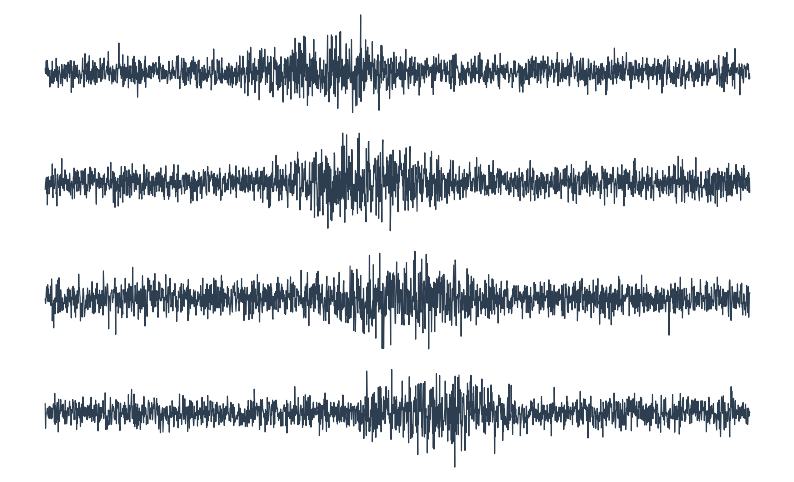

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Set seed for reproducibility
np.random.seed(42)

# Parameters
fs = 1000  # Sampling frequency
duration = 2.0  # Seconds
t = np.linspace(0, duration, int(fs * duration))
n_channels = 4

# Create figure
fig, axes = plt.subplots(n_channels, 1, figsize=(10, 6), sharex=True)
plt.subplots_adjust(hspace=0.1) # Tighten the vertical space

for i in range(n_channels):
    # Generate baseline noise
    emg = np.random.normal(0, 0.05, size=len(t))
    
    # Add a "burst" of activity in the middle
    burst_start = int(fs * (0.5 + i*0.1)) # Offset bursts slightly
    burst_end = burst_start + int(fs * 0.6)
    
    # Envelope for the burst
    envelope = np.zeros_like(t)
    envelope[burst_start:burst_end] = np.sin(np.linspace(0, np.pi, burst_end - burst_start))
    
    # Higher frequency activity within the burst
    activity = np.random.normal(0, 0.1, size=len(t)) * envelope
    emg += activity
    
    # Plotting
    axes[i].plot(t, emg, color='#2c3e50', lw=0.8)
    
    # Remove all labels/titles/spines for a "Clipart" look
    axes[i].axis('off')

# Save or show
# plt.savefig('emg_channels.png', transparent=True, dpi=300)
plt.show()